# Machine Learning Lab
## Text Classification: Emotion Classification

**Idea:** a classifier cannot read words, so we turn each text into a row of numbers (**features**) and then follow the usual ML workflow.

`Text → clean → split → features (BoW / TF-IDF) → train → evaluate → predict new text`

**Dataset:** [Text Emotion (Kaggle)](https://www.kaggle.com/datasets/prajwalnayakat/text-emotion). Each row is a short text with an emotion label.

### 1. Data Collection

In [40]:
#%pip install -q kagglehub scikit-learn pandas matplotlib   # uncomment if a library is missing
import os, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Option A: download from Kaggle with kagglehub
# Option B: download the CSV from the Kaggle page and place it next to this notebook
try:
    import kagglehub
    DATA_DIR = kagglehub.dataset_download("prajwalnayakat/text-emotion")
except Exception as e:
    print("kagglehub not available, looking in the current folder:", e)
    DATA_DIR = "."

files = sorted(glob.glob(os.path.join(DATA_DIR, "**", "*.csv"), recursive=True))
print("CSV files found:", files)

CSV files found: ['C:\\Users\\U-ser\\.cache\\kagglehub\\datasets\\prajwalnayakat\\text-emotion\\versions\\1\\final_dataset.csv']


In [41]:
CSV_PATH = files[0]   # if there are several files, choose the right one here
df = pd.read_csv(CSV_PATH)
print("Shape:", df.shape)
df.head()

Shape: (106355, 2)


,text,emotion
0,i feel rather funny ending with so many dupes ...,fun
1,i feel surprised by the result,surprise
2,i am officially feeling festive,neutral
3,i suddenly found myself standing before this w...,surprise
4,i look at the meager pile of food i purchased ...,enthusiasm


Find the **text column** (the feature source) and the **label column** (the target). The code guesses them; if the guess is wrong, set `TEXT_COL` / `LABEL_COL` yourself.

In [42]:
TEXT_COL, LABEL_COL = None, None   # e.g. TEXT_COL, LABEL_COL = "text", "label"

if TEXT_COL is None:   # the text column has the longest strings
    TEXT_COL = max(df.select_dtypes(include="object").columns,
                   key=lambda c: df[c].astype(str).str.len().mean())
if LABEL_COL is None:  # the label column has the fewest distinct values
    LABEL_COL = min([c for c in df.columns if c != TEXT_COL], key=lambda c: df[c].nunique())
print("Text column :", TEXT_COL)
print("Label column:", LABEL_COL)

Text column : text
Label column: emotion


C:\Users\U-ser\AppData\Local\Temp\ipykernel_9452\198447531.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  TEXT_COL = max(df.select_dtypes(include="object").columns,


#### Dataset overview
Before modeling, understand what one row is. This is a **supervised, multi-class classification** problem:

| Part | Column | Role | Type |
|---|---|---|---|
| Input (features, X) | the text column | the sentence the model reads | string |
| Target (label, y) | the label column | the emotion to predict | category |

Each row is one **sample**: one text and its emotion. Check the columns, types, missing values and duplicates first.

In [43]:
print(f"Rows (samples): {len(df)} | Columns: {list(df.columns)}\n")
print(df.dtypes, "\n")
print("Missing values per column:\n", df.isna().sum(), "\n")
print("Duplicated texts:", df.duplicated(subset=[TEXT_COL]).sum())
print("Number of emotions (classes):", df[LABEL_COL].nunique())

words_per_text = df[TEXT_COL].astype(str).str.split().str.len()
print("\nWords per text:"); print(words_per_text.describe().round(1))
df.sample(5, random_state=1)[[TEXT_COL, LABEL_COL]]

Rows (samples): 106355 | Columns: ['text', 'emotion']

text       str
emotion    str
dtype: object 

Missing values per column:
 text       0
emotion    0
dtype: int64 

Duplicated texts: 25569
Number of emotions (classes): 11

Words per text:
count    106355.0
mean         20.2
std          11.5
min           1.0
25%          12.0
50%          18.0
75%          26.0
max         178.0
Name: text, dtype: float64


,text,emotion
62724,Ok i take it back! Brilliant eve with whyitsgr...,happiness
106161,i feel like it did hit i m glad they avoided o...,empty
19191,i was sitting on a toilet feeling surprised an...,surprise
79890,- Gotta a show on Monday at 9.... hopefully my...,sadness
99856,"Once Monday rolls around, my life after school...",happiness


#### Clean and check the class balance
Remove rows with missing values and duplicated texts (a duplicate can land in both train and test and inflate the score). Then check the **class balance**: if one emotion dominates, accuracy alone is misleading.

emotion
neutral       9906
sadness       9311
happiness     9149
love          8579
surprise      7909
anger         7464
relief        7276
fun           6237
hate          6206
enthusiasm    5247
empty         3502
Name: count, dtype: int64


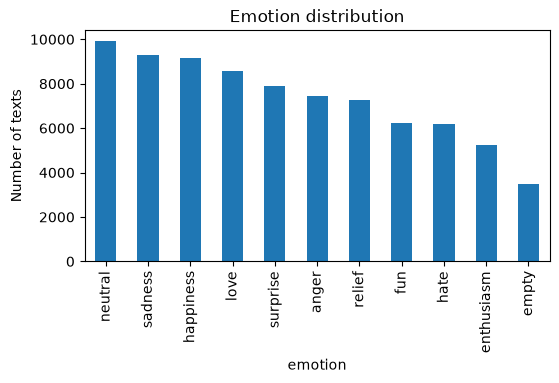

In [44]:
df = df.dropna(subset=[TEXT_COL, LABEL_COL]).drop_duplicates(subset=[TEXT_COL])

counts = df[LABEL_COL].value_counts()
print(counts)
counts.plot(kind="bar", title="Emotion distribution", figsize=(6, 3))
plt.ylabel("Number of texts"); plt.show()

### 2. Data (Text) Preprocessing and Train/Test Split
**Why preprocess?** Raw text is noisy. Without cleaning, `Happy`, `happy!` and `HAPPY` would become three different features.

| Step | Why |
|---|---|
| Lowercase | `Happy` and `happy` are the same word |
| Remove URLs, emails, numbers, punctuation | noise that carries no emotion |
| Remove stop words (`the`, `is`, `and`) | very common words that appear in every emotion |
| Keep negations (`not`, `no`, `never`) | "not happy" means the opposite of "happy" |
| Drop 1-letter tokens | leftovers from cleaning |

In [45]:
import re
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

STOP_WORDS = set(ENGLISH_STOP_WORDS) - {"not", "no", "never", "nor"}

def preprocess_text(text):
    text = text.lower()
    text = re.sub(r"http\S+|\S+@\S+", " ", text)   # remove URLs and emails
    text = text.replace("'", "")                      # don't -> dont
    text = re.sub(r"[^a-z\s]", " ", text)             # remove numbers and punctuation
    tokens = [t for t in text.split() if t not in STOP_WORDS and len(t) > 1]
    return " ".join(tokens)

print(df[TEXT_COL].iloc[0])
print(preprocess_text(str(df[TEXT_COL].iloc[0])))

i feel rather funny ending with so many dupes while i always prefer originals
feel funny ending dupes prefer originals


**Why split?** A model must be judged on texts it has never seen, otherwise we only measure memorization (overfitting).
- **Train (80%)**: the model learns from these.
- **Test (20%)**: kept aside for the final evaluation.
- **Split before vectorizing**: the vocabulary and IDF weights must be learned from training texts only. If test texts influence them, information leaks and the score looks better than it really is (**data leakage**).
- **`stratify`** keeps the same emotion proportions in both sets; **`random_state`** makes the split reproducible.

In [46]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
y = le.fit_transform(df[LABEL_COL].astype(str))   # emotion name -> number
class_names = le.classes_

train_texts, test_texts, train_labels, test_labels = train_test_split(
    df[TEXT_COL].astype(str).tolist(), y,
    test_size=0.2, random_state=82, stratify=y)   # stratify keeps class proportions

processed_train_texts = [preprocess_text(t) for t in train_texts]
processed_test_texts  = [preprocess_text(t) for t in test_texts]
print(f"Train: {len(train_texts)} texts | Test: {len(test_texts)} texts")
print("Classes:", list(class_names))

Train: 64628 texts | Test: 16158 texts
Classes: ['anger', 'empty', 'enthusiasm', 'fun', 'happiness', 'hate', 'love', 'neutral', 'relief', 'sadness', 'surprise']


### 3. Feature Extraction (Bag of Words vs. TF-IDF)
A model needs numbers, not words. Toy example with two texts, `happy happy day` and `sad day`:

| | day | happy | sad |
|---|---|---|---|
| text 1 | 1 | 2 | 0 |
| text 2 | 1 | 0 | 1 |

**TF-IDF** starts from the same counts but down-weights words that appear in many texts (like `day`), so rarer and more informative words weigh more.

#### Bag of Words
Settings used below: `max_features=2000` keeps the 2000 most frequent words; `max_df=0.8` ignores words found in more than 80% of texts (too common to help); `min_df=3` ignores words found in fewer than 3 texts (typos and rare noise).

In [47]:
from sklearn.feature_extraction.text import CountVectorizer

bow_vectorizer = CountVectorizer(max_features=2000, max_df=0.8, min_df=3)
X_train_bow = bow_vectorizer.fit_transform(processed_train_texts)   # learn vocabulary from TRAIN only

print("Vocabulary (first 20):", bow_vectorizer.get_feature_names_out()[:20])
print("Size of matrix:", X_train_bow.shape, "= (texts, words)")

Vocabulary (first 20): ['ability' 'able' 'absolutely' 'abused' 'accept' 'acceptable' 'accepted'
 'accident' 'accomplished' 'account' 'ache' 'achieved' 'aching' 'act'
 'acting' 'action' 'actions' 'activities' 'actual' 'actually']
Size of matrix: (64628, 2000) = (texts, words)


Look inside the matrix: for text 0, which words (columns) are non-zero and how many times?

In [48]:
feature_names = bow_vectorizer.get_feature_names_out()

print("Original :", train_texts[0])
print("Processed:", processed_train_texts[0])

row = X_train_bow[0]                     # sparse row: only non-zero entries are stored
for col_idx, val in zip(row.indices, row.data):
    print(f"column {col_idx} -> '{feature_names[col_idx]}': {val}")

Original : its because we run on CPT!!!
Processed: run cpt
column 1474 -> 'run': 1


In [49]:
# TODO: Do the same for another text (e.g. index 10). Does the vector match the processed text?
# Show text number 10 of the training set, before and after cleaning
print("Original :", train_texts[10])
print("Processed:", processed_train_texts[10])

# Look at the Bag of Words row of text 10:
# which words (columns) are non-zero, and how many times each appears
row = X_train_bow[10]
for col_idx, val in zip(row.indices, row.data):
    print(f"column {col_idx} -> '{feature_names[col_idx]}': {val}")

# ANSWER: Yes, the vector matches the processed text. The processed text is "started feeling kinda funny", and the vector has exactly 4 non-zero columns: 'feeling', 'started', 'kinda' and 'funny', each with the count 1.

Original : i started feeling kinda funny
Processed: started feeling kinda funny
column 612 -> 'feeling': 1
column 1639 -> 'started': 1
column 951 -> 'kinda': 1
column 687 -> 'funny': 1


#### TF-IDF

In [50]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf_vectorizer = TfidfVectorizer(max_features=2000, max_df=0.8, min_df=3)
X_train_tfidf = tfidf_vectorizer.fit_transform(processed_train_texts)

print("Size of matrix:", X_train_tfidf.shape)
print(X_train_tfidf[0])

Size of matrix: (64628, 2000)
<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 1 stored elements and shape (1, 2000)>
  Coords	Values
  (0, 1474)	1.0


In [51]:
# TODO: Print the words and TF-IDF weights of text 0 (like the BoW cell above). Which word has the highest weight? Why?
# The list of words (columns) that the TF-IDF vectorizer knows
tfidf_names = tfidf_vectorizer.get_feature_names_out()

# Show text 0 of the training set, before and after cleaning
print("Original :", train_texts[0])
print("Processed:", processed_train_texts[0])

# Show which words are non-zero in the TF-IDF row of text 0, and their weights
row = X_train_tfidf[0]
for col_idx, val in zip(row.indices, row.data):
    print(f"column {col_idx} -> '{tfidf_names[col_idx]}': {round(val, 4)}")

# ANSWER: The word 'run' has the highest weight (1.0). The processed text is "run cpt", but 'cpt' is too rare to be in the 2000-word vocabulary, so 'run' is the only known word. TF-IDF rows are normalized to length 1, so a single word always gets the weight 1.0.

Original : its because we run on CPT!!!
Processed: run cpt
column 1474 -> 'run': 1.0


### 4. Model Training
**Multinomial Naive Bayes** scores each emotion for a text: `P(emotion) × P(word1 | emotion) × P(word2 | emotion) × ...` and predicts the emotion with the highest score. It is "naive" because it treats words as independent. It trains in a blink and works well with word-count features, which makes it a good baseline. Other classifiers are compared in the optional extension at the end.

In [52]:
from sklearn.naive_bayes import MultinomialNB

classifier_bow = MultinomialNB().fit(X_train_bow, train_labels)
classifier_tfidf = MultinomialNB().fit(X_train_tfidf, train_labels)

def show_top_words(classifier, vectorizer, n=10):
    names = vectorizer.get_feature_names_out()
    for i, emotion in enumerate(class_names[classifier.classes_]):
        top = classifier.feature_log_prob_[i].argsort()[-n:][::-1]   # feature_log_prob_ = log P(word | class)
        print(f"{emotion}: {', '.join(names[top])}")

print("Top words per emotion (Bag of Words):");  show_top_words(classifier_bow, bow_vectorizer)
print("\nTop words per emotion (TF-IDF):");       show_top_words(classifier_tfidf, tfidf_vectorizer)

Top words per emotion (Bag of Words):
anger: feel, angry, feeling, discouraged, not, im, like, just, outraged, time
empty: feel, feeling, avoid, like, im, just, not, know, want, time
enthusiasm: excited, feel, feeling, eager, im, like, not, really, just, time
fun: feel, funny, feeling, fun, joyful, like, im, not, just, really
happiness: feel, happy, feeling, im, like, not, just, enjoy, content, unhappy
hate: feel, hate, feeling, like, hated, im, not, just, hateful, really
love: feel, love, feeling, like, loved, im, not, just, lovely, beloved
neutral: feel, feeling, like, im, not, just, really, know, little, time
relief: feel, feeling, comfortable, uncomfortable, pleased, im, not, like, just, really
sadness: feel, feeling, sad, im, not, depressed, just, like, melancholy, time
surprise: feel, surprised, shocked, feeling, im, like, not, just, know, really

Top words per emotion (TF-IDF):
anger: angry, discouraged, feel, feeling, not, outraged, enraged, im, like, just
empty: feel, avoid, f

### 5. Model Evaluation
Transform the test texts with the **already fitted** vectorizers (`transform`, not `fit_transform`).

| Metric | Question it answers |
|---|---|
| Accuracy | Of all test texts, how many were right? |
| Precision | Of the texts predicted as an emotion, how many truly have it? |
| Recall | Of the texts that truly have an emotion, how many did we find? |
| F1 | One score balancing precision and recall |
| Macro F1 | The average F1 over all emotions, so small emotions count equally |

The **confusion matrix** shows, for each true emotion (rows), which emotion the model predicted (columns).

=== Bag of Words ===
              precision    recall  f1-score   support

       anger       0.74      0.74      0.74      1493
       empty       0.63      0.34      0.44       700
  enthusiasm       0.80      0.82      0.81      1050
         fun       0.80      0.69      0.75      1248
   happiness       0.64      0.67      0.65      1830
        hate       0.79      0.71      0.75      1241
        love       0.76      0.86      0.81      1716
     neutral       0.61      0.60      0.61      1981
      relief       0.85      0.77      0.81      1455
     sadness       0.59      0.66      0.62      1862
    surprise       0.57      0.66      0.61      1582

    accuracy                           0.69     16158
   macro avg       0.71      0.68      0.69     16158
weighted avg       0.70      0.69      0.69     16158



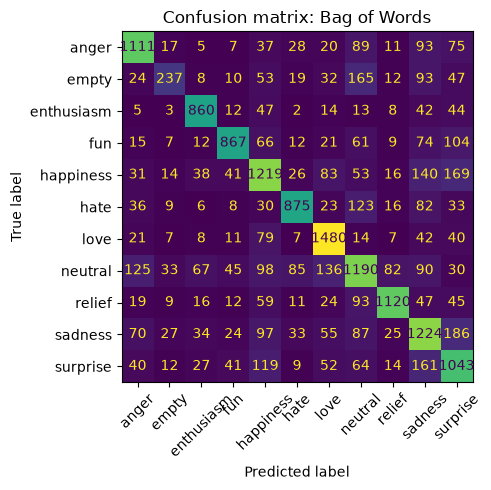

=== TF-IDF ===
              precision    recall  f1-score   support

       anger       0.76      0.71      0.73      1493
       empty       0.89      0.24      0.38       700
  enthusiasm       0.86      0.73      0.79      1050
         fun       0.85      0.62      0.72      1248
   happiness       0.58      0.67      0.62      1830
        hate       0.85      0.64      0.73      1241
        love       0.70      0.83      0.76      1716
     neutral       0.58      0.65      0.61      1981
      relief       0.85      0.74      0.79      1455
     sadness       0.52      0.69      0.59      1862
    surprise       0.58      0.64      0.61      1582

    accuracy                           0.67     16158
   macro avg       0.73      0.65      0.67     16158
weighted avg       0.70      0.67      0.67     16158



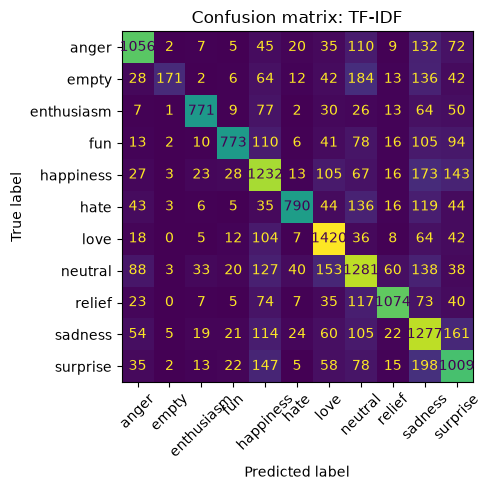

In [53]:
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

X_test_bow   = bow_vectorizer.transform(processed_test_texts)
X_test_tfidf = tfidf_vectorizer.transform(processed_test_texts)

def evaluate(name, classifier, X_test):
    pred = classifier.predict(X_test)
    print(f"=== {name} ===")
    print(classification_report(test_labels, pred, target_names=class_names, zero_division=0))
    fig, ax = plt.subplots(figsize=(6, 5))
    ConfusionMatrixDisplay.from_predictions(test_labels, pred, display_labels=class_names,
                                            ax=ax, colorbar=False, xticks_rotation=45)
    ax.set_title(f"Confusion matrix: {name}")
    plt.tight_layout(); plt.show()
    return pred

predictions_bow   = evaluate("Bag of Words", classifier_bow, X_test_bow)
predictions_tfidf = evaluate("TF-IDF", classifier_tfidf, X_test_tfidf)

In [54]:
pd.DataFrame({
    "Features": ["Bag of Words", "TF-IDF"],
    "Accuracy": [accuracy_score(test_labels, predictions_bow), accuracy_score(test_labels, predictions_tfidf)],
    "Macro F1": [f1_score(test_labels, predictions_bow, average="macro"),
                 f1_score(test_labels, predictions_tfidf, average="macro")],
}).round(3)

,Features,Accuracy,Macro F1
0,Bag of Words,0.695,0.690
1,TF-IDF,0.672,0.667


**Check:** if the classes are imbalanced, accuracy can look good while small emotions are missed. Compare accuracy with **macro F1** and the per-class recall in the report.

#### Printing Results

In [55]:
proba_bow   = classifier_bow.predict_proba(X_test_bow)
proba_tfidf = classifier_tfidf.predict_proba(X_test_tfidf)

for i in range(5):
    print(f"Text {i+1}: {test_texts[i][:100]}")
    print(f"  Actual: {class_names[test_labels[i]]}")
    for name, pred, proba in [("BoW  ", predictions_bow, proba_bow), ("TFIDF", predictions_tfidf, proba_tfidf)]:
        mark = "✓" if pred[i] == test_labels[i] else "✗"
        print(f"  {name}: {class_names[pred[i]]} (confidence {proba[i].max():.3f}) {mark}")
    print("-" * 50)

Text 1: i have exactly weeks to train and prepare which is perfect and so now with week one almost done im f
  Actual: enthusiasm
  BoW  : enthusiasm (confidence 1.000) ✓
  TFIDF: enthusiasm (confidence 0.584) ✓
--------------------------------------------------
Text 2: i am so tired that i am too tired to have energy to feel all the feelings brewing in my troubled lit
  Actual: neutral
  BoW  : neutral (confidence 0.345) ✓
  TFIDF: neutral (confidence 0.188) ✓
--------------------------------------------------
Text 3: i feel eager to keep trying to improve the marketing for it
  Actual: enthusiasm
  BoW  : enthusiasm (confidence 0.993) ✓
  TFIDF: enthusiasm (confidence 0.679) ✓
--------------------------------------------------
Text 4: i guess after surviving getting his balls knocked in on PPV rape and murder just didn't seem as viol
  Actual: anger
  BoW  : neutral (confidence 0.240) ✗
  TFIDF: neutral (confidence 0.205) ✗
--------------------------------------------------
Text 5: i

### 6. Predicting Custom Data
Try the trained models on new sentences that are not in the dataset.

In [56]:
def predict_custom_text(custom_texts, vectorizer, classifier):
    X_new = vectorizer.transform([preprocess_text(t) for t in custom_texts])
    pred, proba = classifier.predict(X_new), classifier.predict_proba(X_new)
    return [(class_names[p], pr.max()) for p, pr in zip(pred, proba)]

custom_texts = [
    "I am so happy today, everything is going wonderfully!",
    "I feel lonely and miserable, I just want to cry.",
    "I am furious, they lied to me again and I hate it.",
    "I am terrified, something is moving in the dark.",
    "I love my family so much, they mean everything to me.",
    "I can't believe it, what a shocking surprise!",
]

bow_results   = predict_custom_text(custom_texts, bow_vectorizer, classifier_bow)
tfidf_results = predict_custom_text(custom_texts, tfidf_vectorizer, classifier_tfidf)

for text, (c1, p1), (c2, p2) in zip(custom_texts, bow_results, tfidf_results):
    print(text)
    print(f"  Bag of Words -> {c1} ({p1:.3f})")
    print(f"  TF-IDF       -> {c2} ({p2:.3f})")
    print("-" * 50)

I am so happy today, everything is going wonderfully!
  Bag of Words -> happiness (0.737)
  TF-IDF       -> happiness (0.451)
--------------------------------------------------
I feel lonely and miserable, I just want to cry.
  Bag of Words -> empty (0.258)
  TF-IDF       -> sadness (0.234)
--------------------------------------------------
I am furious, they lied to me again and I hate it.
  Bag of Words -> hate (0.806)
  TF-IDF       -> hate (0.414)
--------------------------------------------------
I am terrified, something is moving in the dark.
  Bag of Words -> neutral (0.236)
  TF-IDF       -> neutral (0.190)
--------------------------------------------------
I love my family so much, they mean everything to me.
  Bag of Words -> love (0.854)
  TF-IDF       -> love (0.434)
--------------------------------------------------
I can't believe it, what a shocking surprise!
  Bag of Words -> surprise (0.940)
  TF-IDF       -> surprise (0.744)
------------------------------------------

In [57]:
# TODO: Write 3 sentences of your own, including one with a negation (e.g. 'I am not happy'). Does the model get them right?
# My own 3 sentences (the second one has a negation: "not happy")
my_texts = [
    "I am really excited about my new job!",
    "I am not happy with how this turned out.",
    "I feel so sad and alone tonight.",
]

# Predict with both models (this function was defined in an earlier cell)
bow_results = predict_custom_text(my_texts, bow_vectorizer, classifier_bow)
tfidf_results = predict_custom_text(my_texts, tfidf_vectorizer, classifier_tfidf)

# Print the sentence, then what each model predicted and how confident it is
for text, (emotion_bow, conf_bow), (emotion_tfidf, conf_tfidf) in zip(my_texts, bow_results, tfidf_results):
    print(text)
    print(f"  Bag of Words -> {emotion_bow} ({conf_bow:.3f})")
    print(f"  TF-IDF       -> {emotion_tfidf} ({conf_tfidf:.3f})")
    print("-" * 50)

# ANSWER: Two of the three sentences were predicted correctly
# ("excited" -> enthusiasm, "sad and alone" -> sadness).
# The negation sentence "I am not happy..." was predicted as happiness by both models, which is wrong.
# The model counts the word "happy" but does not understand that "not" reverses its meaning,
# because Bag of Words and TF-IDF ignore word order.

I am really excited about my new job!
  Bag of Words -> enthusiasm (0.983)
  TF-IDF       -> enthusiasm (0.585)
--------------------------------------------------
I am not happy with how this turned out.
  Bag of Words -> happiness (0.555)
  TF-IDF       -> happiness (0.307)
--------------------------------------------------
I feel so sad and alone tonight.
  Bag of Words -> sadness (0.950)
  TF-IDF       -> sadness (0.758)
--------------------------------------------------


### 7. Optional Extension: Compare Classifiers
Same features, different model. Which one gives the best macro F1?

In [58]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

for name, clf in [("Multinomial NB", MultinomialNB()),
                  ("Logistic Regression", LogisticRegression(max_iter=1000)),
                  ("Linear SVM", LinearSVC())]:
    clf.fit(X_train_tfidf, train_labels)
    pred = clf.predict(X_test_tfidf)
    print(f"{name:20s} accuracy={accuracy_score(test_labels, pred):.3f}  macro F1={f1_score(test_labels, pred, average='macro'):.3f}")

Multinomial NB       accuracy=0.672  macro F1=0.667
Logistic Regression  accuracy=0.758  macro F1=0.753
Linear SVM           accuracy=0.756  macro F1=0.751


### Student Practices
1. Why did we split the data *before* fitting the vectorizer?

Answer: The vectorizer learns the vocabulary (which words exist) and, for TF-IDF, the IDF weights (how rare each word is) from the texts it is fitted on. If we fitted it on all the data before splitting, the test texts would influence the vocabulary and the weights, so the model would indirectly "see" information from the test set. This is called data leakage, and it makes the test score look better than it really is. By splitting first, and fitting the vectorizer on the training texts only (then using `transform` on the test texts), the test set stays completely unseen, so the evaluation is honest and shows how the model would perform on new texts.


2. Did TF-IDF beat Bag of Words? Which metric did you use to decide, and why?

Answer: No, TF-IDF did not beat Bag of Words in this experiment with Multinomial Naive Bayes. Bag of Words reached an accuracy of 0.695 and a macro F1 of 0.690, while TF-IDF reached an accuracy of 0.672 and a macro F1 of 0.667, so Bag of Words was better on both metrics (by about 2.3 percentage points). I used the **macro F1** to decide (and compared it with accuracy), because macro F1 is the average of the F1 score of every emotion, so each of the 11 emotions counts equally, even the small ones. Accuracy can look good when a model is right mostly on the biggest classes, but macro F1 shows whether it works for all emotions. A possible reason is that Multinomial Naive Bayes is designed for word counts, and TF-IDF reduces the weight of common words like "feel" that still help to identify the emotion in this dataset.


3. Which emotions are confused with each other in the confusion matrix, and why might that happen?

Answer: In the Bag of Words confusion matrix, the biggest confusions are between happiness, sadness, and surprise: for example, sadness was predicted as surprise 186 times, happiness as surprise 169 times, surprise as sadness 161 times, and happiness as sadness 140 times. The emotion "empty" is also very often confused with "neutral" (165 of its 700 test texts were predicted as neutral, and only 237 were correct, a recall of 0.34), and "neutral" is confused with many other emotions such as love (136), anger (125), and happiness (98). The emotions with clear signal words, such as love, enthusiasm, and relief, are predicted much better (for example, love has a recall of 0.86).

This may happen for several reasons. First, the "Top words per emotion" output shows that the most frequent words in almost every emotion are the same (feel, feeling, im, like, not, just), so most words do not help to tell the emotions apart. Only a few words are specific to an emotion (for example, "angry", "happy", "sad"). Second, the texts are short, so many texts contain none of these specific words. Third, emotions like "empty" and "neutral" have no strong emotion words, and happiness, sadness, and surprise are often expressed with similar sentence patterns ("i feel ..."). Finally, Naive Bayes treats words as independent and counts them without understanding the meaning or order, so it cannot see context such as negation.


4. Find a solution that improves the accuracy above that of all three models above. Report the accuracy of the three original models, your best accuracy, and briefly explain what you changed and why you think it helped.

Answer:

**Accuracy of the three original models (TF-IDF features, 2000 words):**

| Model | Accuracy |
|---|---|
| Multinomial Naive Bayes | 0.672 |
| Logistic Regression | 0.758 |
| Linear SVM | 0.756 |

**My best accuracy: 0.771** (macro F1 = 0.766), using Logistic Regression with TF-IDF features and no limit on the number of words (12,852 features instead of 2000).

**What I changed:** I removed `max_features=2000` from the TF-IDF vectorizer, so the model could use every word that appears in at least 3 texts and in less than 80% of the texts (`min_df=3`, `max_df=0.8`), and I trained Logistic Regression on these features. I still fitted the vectorizer on the training texts only, so there was no data leakage.

**Why I think it helped:** With only 2000 words, many words that are strongly linked to one emotion (for example rarer words such as "outraged", "melancholy" or "beloved") were thrown away, and many texts ended up with very few non-zero words. With 12,852 words, the model sees more of these emotion-specific words, so it can tell similar emotions apart better. Logistic Regression also learns a weight for every word directly to separate the emotions, so it uses these extra words better than Naive Bayes. Keeping `min_df=3` still removes typos and very rare noise.



In [59]:
# Experiment A: keep ALL useful words instead of only the top 2000
# (no max_features, so the model sees many more words)
tfidf_a = TfidfVectorizer(max_df=0.8, min_df=3)
X_train_a = tfidf_a.fit_transform(processed_train_texts)   # learn vocabulary from TRAIN only
X_test_a = tfidf_a.transform(processed_test_texts)         # only transform the test texts
print("Number of features:", X_train_a.shape[1])

# Train Logistic Regression (the best of the original models) on the bigger feature set
clf_a = LogisticRegression(max_iter=1000)
clf_a.fit(X_train_a, train_labels)
pred_a = clf_a.predict(X_test_a)

# Show the scores
print(f"Experiment A: accuracy={accuracy_score(test_labels, pred_a):.3f}  macro F1={f1_score(test_labels, pred_a, average='macro'):.3f}")

Number of features: 12852
Experiment A: accuracy=0.771  macro F1=0.766
